# Tallinn Livability Score — Notebook 2: Building Quality (Reference Only)

This notebook computes `building_quality_score` from energy performance,
for every residential apartment building in `tallinn_livability_base.gpkg`.

**Energy score and construction/renovation timeline were both originally
intended as scoring factors, and neither made it into the final score.**
This notebook computes and saves `building_quality_score` anyway — it's
genuinely useful, shown on the map and in attributes — but it is
**display-only**; notebook 3's final aggregation uses the 4 proximity
factors exclusively. See the published methodology document for the full
reasoning; summary:

1. **Construction/renovation timeline**: dropped first. We have no true
   renovation date, only construction year, and construction year turned
   out to be a weak, non-monotonic quality signal for ~90% of the stock
   (mean energy class is roughly flat across the 1880s-2000s, only rising
   for 2010s+ new-build) — see section 4 below for the evidence.
2. **Energy class**: only 48.5% of buildings have a real certificate.
   Excluding it per-building and renormalizing the remaining factors (an
   approach tried in an earlier version of this pipeline) turned out to
   quietly *favor* buildings without a certificate, since building quality
   is negatively correlated with proximity in Tallinn — buildings missing
   the factor skipped the one dimension most likely to pull their score
   down. Imputing a value instead would mean scoring a model guess as if
   it were measured. Neither was acceptable, so energy score was removed
   from scoring entirely rather than compromised into the aggregate.

A group-median imputation model is still built and validated here (it's
genuinely informative on its own terms), but its output stays a clearly
labeled **reference-only** column, never used in any score.


## 1. Imports

In [1]:
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", None)


## 2. CONFIG

In [2]:
DATA_DIR = Path("./data")
INPUT_GPKG  = DATA_DIR / "tallinn_livability_base.gpkg"
INPUT_LAYER = "buildings"
OUTPUT_GPKG = DATA_DIR / "tallinn_livability_base.gpkg"
OUTPUT_LAYER = "buildings_scored"

ENERGY_COL = "energiaklass"
YEAR_COL   = "esmane_kasutus"

# EU EPC scale: A = most efficient (best) ... H = least efficient (worst)
ENERGY_SCALE = {"A": 8, "B": 7, "C": 6, "D": 5, "E": 4, "F": 3, "G": 2, "H": 1}

# Winsorizing percentiles for normalization (per OECD Handbook recommendation)
WINSOR_LOW, WINSOR_HIGH = 0.05, 0.95


## 3. Load buildings

Output of notebook 1 — residential apartment buildings, clipped to Tallinn,
with `energiaklass` already attached from Maa-amet's `etak_ehr_hooned` WFS
layer.


In [3]:
buildings = gpd.read_file(INPUT_GPKG, layer=INPUT_LAYER)
print(f"Loaded {len(buildings):,} buildings. CRS: {buildings.crs}")
print(f"With {ENERGY_COL}: {buildings[ENERGY_COL].notna().sum():,} "
      f"({buildings[ENERGY_COL].notna().mean():.1%})")


Loaded 7,842 buildings. CRS: EPSG:4326
With energiaklass: 3,807 (48.5%)


## 4. Derived attributes: energy (ordinal), construction decade, district

- `energy_numeric` — `energiaklass` mapped A→8 ... H→1 (higher = better).
- `decade_bin` — construction decade from `esmane_kasutus` (0 = bad sentinel
  treated as missing).
- `district` — parsed from `taisaadress` (Tallinn's 8 linnaosad).

These three feed both the imputation model (section 5) and the normalized
scores (section 6).


In [4]:
buildings["energy_numeric"] = buildings[ENERGY_COL].map(ENERGY_SCALE)

year = buildings[YEAR_COL].replace(0, np.nan)
buildings["decade_bin"] = (year // 10 * 10)
buildings["district"] = buildings["taisaadress"].str.split(", ").str[2]

print(buildings[["energy_numeric", "decade_bin", "district"]].describe(include="all"))


        energy_numeric   decade_bin            district
count      3807.000000  7585.000000                7842
unique             NaN          NaN                   8
top                NaN          NaN  Kesklinna linnaosa
freq               NaN          NaN                2073
mean          4.892304  1957.737640                 NaN
std           1.494063    40.755293                 NaN
min           1.000000  1340.000000                 NaN
25%           4.000000  1940.000000                 NaN
50%           5.000000  1960.000000                 NaN
75%           6.000000  1980.000000                 NaN
max           8.000000  2020.000000                 NaN


## 5. Impute missing energy class — reference only, not used in the score

The 51% of buildings without a certificate aren't a random subset — they
skew older, smaller, and cluster in specific districts (Nõmme, Pirita,
Kesklinn). We build a group-median imputation model (by `decade_bin` x
`district`, falling back to `district` → `decade_bin` → global median) and
validate it on held-out labeled data, purely to have an honest answer to
"how good would a guess be" — its output is saved as
`energy_numeric_imputed_reference`, kept separate from the real
`energy_numeric` and **not** used to compute `building_quality_score`
below.


In [5]:
labeled = buildings.dropna(subset=["energy_numeric"]).copy()

# Holdout validation (80/20 split) — confirms the imputation approach is
# actually better than a naive baseline before trusting it for anything.
rng = np.random.default_rng(42)
idx = labeled.index.to_numpy().copy()
rng.shuffle(idx)
split = int(len(idx) * 0.8)
train, test = labeled.loc[idx[:split]], labeled.loc[idx[split:]]

def fit_group_medians(df):
    return (
        df.groupby(["decade_bin", "district"])["energy_numeric"].median(),
        df.groupby("district")["energy_numeric"].median(),
        df.groupby("decade_bin")["energy_numeric"].median(),
        df["energy_numeric"].median(),
    )

def predict_energy(row, group_med, district_med, decade_med, global_med):
    key = (row["decade_bin"], row["district"])
    if key in group_med.index and pd.notna(group_med.loc[key]):
        return group_med.loc[key]
    if row["district"] in district_med.index:
        return district_med.loc[row["district"]]
    if row["decade_bin"] in decade_med.index:
        return decade_med.loc[row["decade_bin"]]
    return global_med

group_med, district_med, decade_med, global_med = fit_group_medians(train)
preds = test.apply(predict_energy, axis=1, args=(group_med, district_med, decade_med, global_med))
mae = (preds - test["energy_numeric"]).abs().mean()
baseline_mae = (global_med - test["energy_numeric"]).abs().mean()
within_1 = ((preds - test["energy_numeric"]).abs() <= 1).mean()
print(f"Holdout MAE: {mae:.2f} classes | naive-baseline MAE: {baseline_mae:.2f} "
      f"| improvement: {(1 - mae/baseline_mae):.1%} | within +/-1 class: {within_1:.1%}")

# Refit on ALL labeled data, then compute the REFERENCE-ONLY imputed value
# for every unlabeled building. energy_is_measured is the flag notebook 3
# (and the map) use to distinguish real data from this guess.
group_med, district_med, decade_med, global_med = fit_group_medians(labeled)
buildings["energy_is_measured"] = buildings["energy_numeric"].notna()
missing_mask = buildings["energy_numeric"].isna()
buildings.loc[missing_mask, "energy_numeric_imputed_reference"] = buildings.loc[missing_mask].apply(
    predict_energy, axis=1, args=(group_med, district_med, decade_med, global_med)
)

print(f"\n{missing_mask.sum():,} buildings ({missing_mask.mean():.1%}) have no certificate; "
      f"reference estimate computed for all of them but NOT used in building_quality_score.")


Holdout MAE: 0.84 classes | naive-baseline MAE: 1.19 | improvement: 29.0% | within +/-1 class: 83.3%

4,035 buildings (51.5%) have no certificate; reference estimate computed for all of them but NOT used in building_quality_score.


## 6. Normalize `building_quality_score` (winsorized min-max, 0–100)

Computed **only from measured `energy_numeric`** — `NaN` where there's no
certificate on file. This is the reusable normalizer notebook 3 also uses
for the proximity factors.


building_quality_score: 3,807 buildings have a real value (48.5%), rest are NaN by design


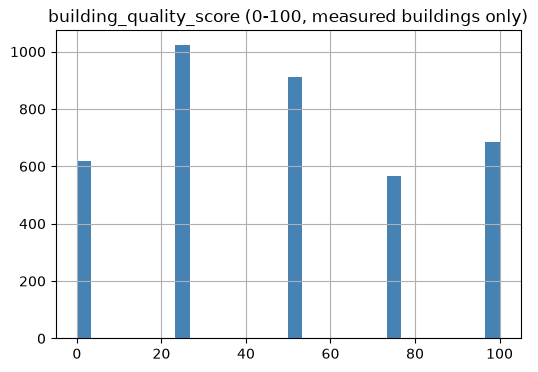

In [6]:
def winsorized_minmax(series, low=WINSOR_LOW, high=WINSOR_HIGH):
    """Winsorized min-max normalization to 0-100. Higher input = higher output.
    NaN in -> NaN out (quantile/clip/arithmetic all propagate NaN)."""
    lo, hi = series.quantile(low), series.quantile(high)
    clipped = series.clip(lo, hi)
    if hi == lo:
        return pd.Series(50.0, index=series.index)  # degenerate case: no spread
    return (clipped - lo) / (hi - lo) * 100

# building_quality_score = normalized energy_numeric, computed ONLY from
# measured values. NaN for the 51% without a certificate -- notebook 3
# excludes this factor (rather than guessing) when aggregating those rows.
buildings["building_quality_score"] = winsorized_minmax(buildings["energy_numeric"])

print(f"building_quality_score: {buildings['building_quality_score'].notna().sum():,} "
      f"buildings have a real value ({buildings['building_quality_score'].notna().mean():.1%}), "
      f"rest are NaN by design")

fig, ax = plt.subplots(figsize=(6, 4))
buildings["building_quality_score"].hist(ax=ax, bins=30, color="steelblue")
ax.set_title("building_quality_score (0-100, measured buildings only)")
plt.show()


## 7. Save

Adds the new columns to a `buildings_scored` layer (keeps `buildings` from
notebook 1 untouched, in case you want to compare or redo this step).


In [7]:
buildings.to_file(OUTPUT_GPKG, layer=OUTPUT_LAYER, driver="GPKG")
print(f"Saved -> {OUTPUT_GPKG}, layer '{OUTPUT_LAYER}' ({len(buildings):,} buildings)")
print("New columns:", [c for c in [
    "energy_numeric", "energy_is_measured", "energy_numeric_imputed_reference",
    "decade_bin", "district", "building_quality_score",
] if c in buildings.columns])


Saved -> data/tallinn_livability_base.gpkg, layer 'buildings_scored' (7,842 buildings)
New columns: ['energy_numeric', 'energy_is_measured', 'energy_numeric_imputed_reference', 'decade_bin', 'district', 'building_quality_score']


## Next steps — notebook 3 (proximity + final aggregation)

1. Compute the four proximity factors (network walking distance +
   logistic distance-decay + `winsorized_minmax()`, same helper as here).
2. Combine per building: if `building_quality_score` is real (48.5% of
   buildings), geometric-mean it with the 4 proximity factors (5 factors,
   equal weight 1/5 each). If it's `NaN` (51.5%), geometric-mean just the
   4 proximity factors instead (renormalized to 1/4 each) — no fabricated
   number enters the score either way.
3. Flag every building's final score with whether building quality was
   included, so the map/output can visually distinguish "full 5-factor
   score" from "4-factor score, no energy data available."
4. Sensitivity analysis (Monte Carlo over weights/decay parameters) and
   AHP/Delphi local weighting remain open next steps beyond that.
